# Deep Learning: Emoji Emotion Classification with Custom CNNs

This project demonstrates the end-to-end process of building a Convolutional Neural Network (CNN) from scratch using PyTorch to classify the emotional state of custom-generated emojis.

## Objective
The goal is to correctly classify an emoji image into one of five categories: `happy`, `sad`, `angry`, `surprised`, and `sleepy`. The project handles challenges such as rotation, noise, and occlusions by implementing robust data augmentation and a stabilized CNN architecture.

## Workflow Overview
1. **Synthetic Dataset Generation:** Procedurally generating emoji images with varying levels of difficulty.
2. **Exploratory Data Analysis (EDA):** Analyzing class distributions and visual variations.
3. **Data Augmentation Pipeline:** Implementing custom PyTorch transforms (rotation, cropping, color jitter, soft noise) to improve generalization.
4. **Baseline CNN:** Designing and training a fundamental 3-block CNN.
5. **Model Evaluation:** Analyzing performance using accuracy, macro F1-score, and confusion matrices.
6. **Error Analysis:** Visualizing misclassifications and feature maps to understand model failures.
7. **Optimized CNN:** Building a deeper, more robust architecture using Batch Normalization and adaptive pooling to improve baseline metrics.

## 1. Libraries and Setup
Importing the required libraries for image processing, neural network construction, and evaluation metrics.

In [1]:
import math
import random
from copy import deepcopy

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from PIL import Image, ImageDraw, ImageFilter, ImageOps, ImageEnhance

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

IMG_SIZE = 64
BATCH_SIZE = 64
NUM_CLASSES = 5
CLASS_NAMES = ["happy", "sad", "angry", "surprised", "sleepy"]

print(f"Device: {device}")
print(f"Class Names: {CLASS_NAMES}")

Device: cuda
Class Names: ['happy', 'sad', 'angry', 'surprised', 'sleepy']


## 2. Synthetic Emoji Dataset Generation
The following functions procedurally generate emoji images for the five target classes. The `hard_mode` parameter introduces additional visual challenges, such as heavier rotation, noise, blur, and occlusions, to test the model's robustness.

In [2]:
def _jitter(rng, low, high):
    return rng.randint(low, high)

def add_soft_noise(img, rng, amount=35):
    arr = np.array(img).astype(np.int16)
    noise = rng.normalvariate(0, 1)
    gaussian = np.random.default_rng(rng.randint(0, 10_000)).normal(0, amount, size=arr.shape)
    arr = np.clip(arr + gaussian, 0, 255).astype(np.uint8)
    return Image.fromarray(arr)

def draw_emoji(label, img_size=64, seed=0, hard_mode=False):
    rng = random.Random(seed)

    bg_color = (
        245 + _jitter(rng, -8, 8),
        245 + _jitter(rng, -8, 8),
        250 + _jitter(rng, -8, 5),
    )
    img = Image.new("RGB", (img_size, img_size), bg_color)
    draw = ImageDraw.Draw(img)

    # background dots
    for _ in range(40 if not hard_mode else 70):
        x = _jitter(rng, 0, img_size - 1)
        y = _jitter(rng, 0, img_size - 1)
        r = _jitter(rng, 1, 2)
        c = 235 + _jitter(rng, -18, 12)
        draw.ellipse((x-r, y-r, x+r, y+r), fill=(c, c, c + _jitter(rng, -5, 5)))

    cx = img_size // 2 + _jitter(rng, -3, 3)
    cy = img_size // 2 + _jitter(rng, -3, 3)
    radius = 22 + _jitter(rng, -2, 2)

    draw.ellipse(
        (cx - radius, cy - radius, cx + radius, cy + radius),
        fill=(252, 215 + _jitter(rng, -12, 8), 70 + _jitter(rng, -10, 8)),
        outline=(120, 90, 20),
        width=2,
    )

    if rng.random() < 0.55:
        cheek_color = (245, 165 + _jitter(rng, -10, 10), 165 + _jitter(rng, -10, 10))
        draw.ellipse((cx - 16, cy + 2, cx - 10, cy + 8), fill=cheek_color)
        draw.ellipse((cx + 10, cy + 2, cx + 16, cy + 8), fill=cheek_color)

    ex = 9 + _jitter(rng, -1, 1)
    ey = 8 + _jitter(rng, -1, 1)

    left_eye = (cx - ex, cy - ey)
    right_eye = (cx + ex, cy - ey)

    def draw_open_eye(center, w=4, h=5):
        x, y = center
        draw.ellipse((x - w//2, y - h//2, x + w//2, y + h//2), fill=(20, 20, 20))

    def draw_closed_eye(center, width=6):
        x, y = center
        draw.line((x - width//2, y, x + width//2, y), fill=(20, 20, 20), width=2)

    def draw_arc_eye(center, start, end, width=2):
        x, y = center
        box = (x - 4, y - 4, x + 4, y + 4)
        draw.arc(box, start=start, end=end, fill=(20, 20, 20), width=width)

    if label == "angry":
        draw.line((left_eye[0] - 5, left_eye[1] - 6, left_eye[0] + 2, left_eye[1] - 8), fill=(80, 40, 10), width=2)
        draw.line((right_eye[0] - 2, right_eye[1] - 8, right_eye[0] + 5, right_eye[1] - 6), fill=(80, 40, 10), width=2)
    elif label == "sad":
        draw.line((left_eye[0] - 5, left_eye[1] - 8, left_eye[0] + 2, left_eye[1] - 6), fill=(80, 40, 10), width=2)
        draw.line((right_eye[0] - 2, right_eye[1] - 6, right_eye[0] + 5, right_eye[1] - 8), fill=(80, 40, 10), width=2)
    elif label == "surprised":
        draw.line((left_eye[0] - 4, left_eye[1] - 8, left_eye[0] + 4, left_eye[1] - 8), fill=(90, 50, 10), width=2)
        draw.line((right_eye[0] - 4, right_eye[1] - 8, right_eye[0] + 4, right_eye[1] - 8), fill=(90, 50, 10), width=2)

    if label == "happy":
        draw_arc_eye(left_eye, 10, 170, width=2)
        draw_arc_eye(right_eye, 10, 170, width=2)
        draw.arc((cx - 11, cy - 1, cx + 11, cy + 15), start=15, end=165, fill=(120, 30, 30), width=3)

    elif label == "sad":
        draw_open_eye(left_eye, 3, 5)
        draw_open_eye(right_eye, 3, 5)
        draw.arc((cx - 11, cy + 8, cx + 11, cy + 20), start=200, end=340, fill=(120, 30, 30), width=3)
        if rng.random() < 0.65:
            # a tear
            tx = left_eye[0] - 2
            ty = left_eye[1] + 6
            draw.ellipse((tx - 2, ty, tx + 2, ty + 6), fill=(100, 180, 255))

    elif label == "angry":
        draw_open_eye(left_eye, 3, 5)
        draw_open_eye(right_eye, 3, 5)
        draw.arc((cx - 10, cy + 7, cx + 10, cy + 19), start=200, end=340, fill=(120, 10, 10), width=3)

    elif label == "surprised":
        draw_open_eye(left_eye, 4, 6)
        draw_open_eye(right_eye, 4, 6)
        mouth_r = 5 + _jitter(rng, -1, 1)
        draw.ellipse((cx - mouth_r, cy + 6, cx + mouth_r, cy + 6 + 2*mouth_r), outline=(120, 30, 30), width=3)

    elif label == "sleepy":
        draw_closed_eye(left_eye, width=7)
        draw_closed_eye(right_eye, width=7)
        draw.arc((cx - 10, cy + 6, cx + 10, cy + 12), start=5, end=175, fill=(120, 30, 30), width=2)
        if rng.random() < 0.5:
            bx = right_eye[0] + 5
            by = right_eye[1] - 2
            draw.ellipse((bx, by, bx + 5, by + 5), outline=(120, 180, 255), width=2)

    if hard_mode and rng.random() < 0.45:
        y0 = cy + _jitter(rng, -3, 6)
        draw.rectangle((cx - 14, y0, cx + 14, y0 + 3), fill=(230, 230, 230))

    img = img.rotate(_jitter(rng, -10, 10) if not hard_mode else _jitter(rng, -18, 18), fillcolor=bg_color)

    if rng.random() < (0.4 if not hard_mode else 0.75):
        img = add_soft_noise(img, rng, amount=14 if not hard_mode else 24)

    if hard_mode and rng.random() < 0.3:
        img = img.filter(ImageFilter.GaussianBlur(radius=0.7))

    return img

## 3. Exploratory Data Analysis (EDA)
Before feeding data into the CNN, it is crucial to inspect the generated samples to understand the visual variance within each class. We will also verify the dataset distribution across the training, validation, and testing splits to ensure a balanced dataset.

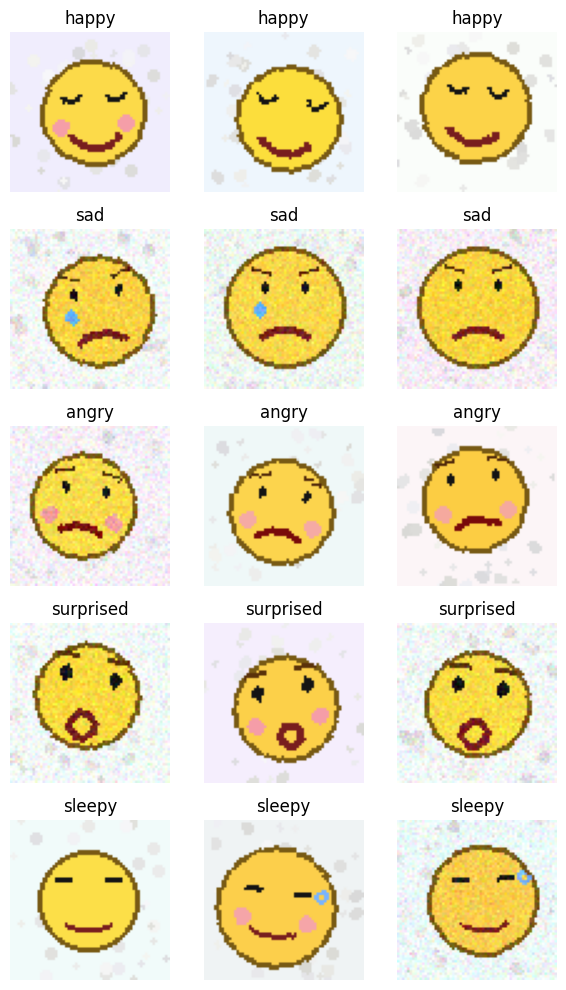

In [3]:
def show_samples_per_class(class_names, samples_per_class=3, hard_mode=False):
    seed = 42
    num_classes = len(class_names)
    fig, axes = plt.subplots(num_classes, samples_per_class, 
                            figsize=(samples_per_class * 2, num_classes * 2), 
                            squeeze=False)
    
    for i, label in enumerate(class_names):
        for j in range(samples_per_class):
            # Generate the emoji image
            img = draw_emoji(label, seed=seed, hard_mode=hard_mode)
            seed += 1
            
            # Display the image
            axes[i, j].imshow(img)
            axes[i, j].axis('off')
            
            # Add the class label as a title to the first column
            axes[i, j].set_title(label)
                
    plt.tight_layout()
    plt.show()

show_samples_per_class(CLASS_NAMES, samples_per_class=3)

,split,label_name,label_idx,seed,hard_mode
0,train,sleepy,4,40103,False
1,train,sad,1,10097,False
2,train,sad,1,10086,False
3,train,sad,1,10249,False
4,train,sad,1,10297,False


,split,label_name,count
0,test,angry,100
1,test,happy,100
2,test,sad,100
3,test,sleepy,100
4,test,surprised,100
5,train,angry,300
6,train,happy,300
7,train,sad,300
8,train,sleepy,300
9,train,surprised,300



--- Summary Table of Sample Counts ---


split,train,val,test
label_name,,,
angry,300,80,100
happy,300,80,100
sad,300,80,100
sleepy,300,80,100
surprised,300,80,100


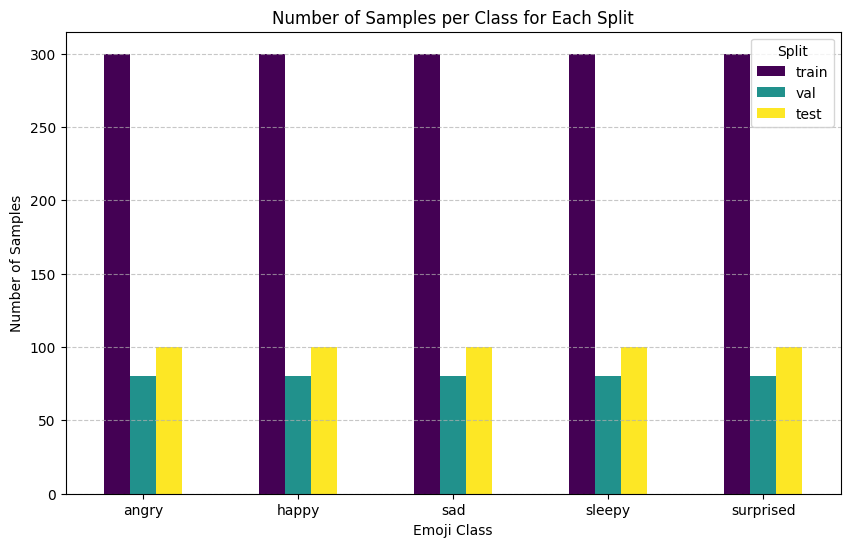

In [4]:
SPLIT_COUNTS = {
    "train": 300,
    "val": 80,
    "test": 100,
}

def build_records(split_name, class_names, counts_per_class, hard_mode=False, seed_offset=0):
    records = []
    label_to_idx = {name: i for i, name in enumerate(class_names)}
    for class_name in class_names:
        label_idx = label_to_idx[class_name]
        for i in range(counts_per_class):
            records.append({
                "split": split_name,
                "label_name": class_name,
                "label_idx": label_idx,
                "seed": seed_offset + 10_000 * label_idx + i,
                "hard_mode": hard_mode,
            })
    random.Random(SEED + seed_offset).shuffle(records)
    return records

# Generate balanced splits
train_records = build_records("train", CLASS_NAMES, SPLIT_COUNTS["train"], hard_mode=False, seed_offset=0)
val_records   = build_records("val", CLASS_NAMES, SPLIT_COUNTS["val"], hard_mode=False, seed_offset=100_000)
test_records  = build_records("test", CLASS_NAMES, SPLIT_COUNTS["test"], hard_mode=False, seed_offset=200_000)

all_records = pd.DataFrame(train_records + val_records + test_records)
display(all_records.head())

count_df = all_records.groupby(["split", "label_name"]).size().reset_index(name="count")
display(count_df)

# Create a pivot table for a cleaner summary view
summary_table = count_df.pivot(index="label_name", columns="split", values="count")
# Reorder columns to a logical sequence
summary_table = summary_table[["train", "val", "test"]] 
print("\n--- Summary Table of Sample Counts ---")
display(summary_table)

# Plotting the sample distribution
summary_table.plot(kind="bar", figsize=(10, 6), colormap="viridis")
plt.title("Number of Samples per Class for Each Split")
plt.xlabel("Emoji Class")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title="Split")
plt.show()

## 4. Preprocessing and Custom Data Augmentation
To prevent the CNN from overfitting to the synthetic training data, we implement a custom augmentation pipeline. 

The `train_transform` applies random horizontal flips, slight rotations, cropping, and color jitter to simulate real-world variance. The `eval_transform` applies strict normalization without stochastic alterations to ensure deterministic evaluation on validation and test sets.

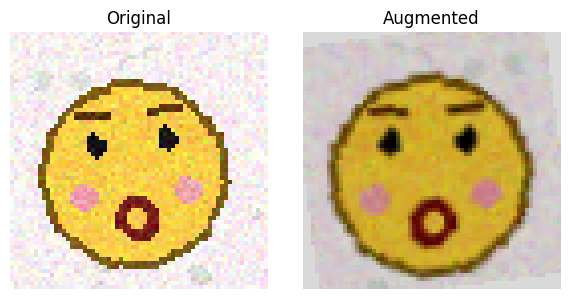

In [5]:
class Compose:
    def __init__(self, transforms):
        self.transforms = transforms

    def __call__(self, img):
        for t in self.transforms:
            img = t(img)
        return img

class Resize:
    def __init__(self, size):
        if isinstance(size, int):
            size = (size, size)
        self.size = size

    def __call__(self, img):
        return img.resize(self.size, Image.BILINEAR)

class RandomHorizontalFlip:
    def __init__(self, p=0.5):
        self.p = p

    def __call__(self, img):
        if random.random() < self.p:
            return img.transpose(Image.FLIP_LEFT_RIGHT)
        return img

class RandomRotation:
    def __init__(self, degrees):
        self.degrees = degrees

    def __call__(self, img):
        angle = random.uniform(-self.degrees, self.degrees)
        return img.rotate(angle, resample=Image.BILINEAR, fillcolor=(255, 255, 255))

class RandomResizedCrop:
    def __init__(self, size, scale=(0.85, 1.0)):
        self.size = (size, size) if isinstance(size, int) else size
        self.scale = scale

    def __call__(self, img):
        w, h = img.size
        s = random.uniform(*self.scale)
        new_w, new_h = int(w * s), int(h * s)

        # Random origin
        x = random.randint(0, w - new_w)
        y = random.randint(0, w - new_h)

        img_cropped = img.crop((x, y, x + new_w, y + new_h))
        return img_cropped.resize(self.size, Image.BILINEAR)

class ColorJitter:
    def __init__(self, brightness=0.0, contrast=0.0, saturation=0.0):
        self.brightness = brightness
        self.contrast = contrast
        self.saturation = saturation

    def __call__(self, img):
        if self.brightness > 0:
            factor = random.uniform(1 - self.brightness, 1 + self.brightness)
            img = ImageEnhance.Brightness(img).enhance(factor)
        if self.contrast > 0:
            factor = random.uniform(1 - self.contrast, 1 + self.contrast)
            img = ImageEnhance.Contrast(img).enhance(factor)
        if self.saturation > 0:
            factor = random.uniform(1 - self.saturation, 1 + self.saturation)
            img = ImageEnhance.Color(img).enhance(factor)
        return img
    
class ToTensorNormalize:
    def __init__(self, mean, std):
        self.mean = np.array(mean, dtype=np.float32).reshape(3, 1, 1)
        self.std = np.array(std, dtype=np.float32).reshape(3, 1, 1)

    def __call__(self, img):
        arr = np.array(img, dtype=np.float32) / 255.0
        # Convert HWC to CHW
        arr = arr.transpose(2, 0, 1)
        arr = (arr - self.mean) / self.std
        return torch.tensor(arr)


train_transform = Compose([
    RandomResizedCrop(IMG_SIZE, scale=(0.85, 1.0)),
    RandomRotation(15),
    RandomHorizontalFlip(p=0.5),
    ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    ToTensorNormalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

eval_transform = Compose([
    Resize(IMG_SIZE),
    ToTensorNormalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

def denormalize(t):
    t = t.clone().cpu()
    for c in range(3):
        t[c] = t[c] * 0.5 + 0.5
    return t.clamp(0, 1)

sample_img = draw_emoji("surprised", img_size=IMG_SIZE, seed=1234)
augmented = train_transform(sample_img)

fig, axes = plt.subplots(1, 2, figsize=(6, 3))

# Original Image
axes[0].imshow(sample_img)
axes[0].set_title("Original")
axes[0].axis('off')

# Augmented Image (requires denormalization and permuting back to HWC)
aug_img_np = denormalize(augmented).permute(1, 2, 0).numpy()
axes[1].imshow(aug_img_np)
axes[1].set_title("Augmented")
axes[1].axis('off')

plt.tight_layout()
plt.show()

## 5. Dataset and DataLoader Configuration
To efficiently feed data into our PyTorch models, we wrap our generated records in custom `Dataset` objects and create `DataLoader` instances for the training, validation, and testing splits.

In [6]:
class EmojiMoodDataset(Dataset):
    def __init__(self, records, transform=None):
        self.records = records
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        rec = self.records[idx]
        img = draw_emoji(
            rec["label_name"],
            img_size=IMG_SIZE,
            seed=rec["seed"],
            hard_mode=rec["hard_mode"],
        )
        if self.transform is not None:
            img = self.transform(img)
        label = rec["label_idx"]
        return img, label

# Instantiate datasets
train_dataset = EmojiMoodDataset(train_records, transform=train_transform)
val_dataset   = EmojiMoodDataset(val_records, transform=eval_transform)
test_dataset  = EmojiMoodDataset(test_records, transform=eval_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

images, labels = next(iter(train_loader))
print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)

Batch image shape: torch.Size([64, 3, 64, 64])
Batch label shape: torch.Size([64])


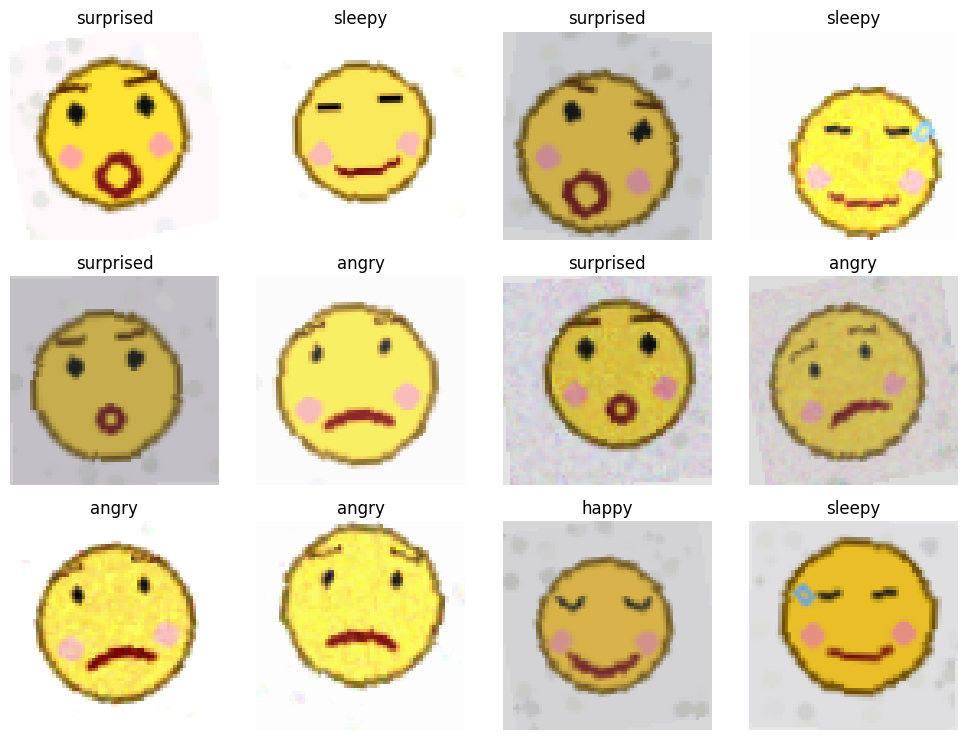

In [7]:
def show_batch(images, labels, class_names, max_items=12):
    num_items = min(len(images), max_items)
    cols = 4
    rows = math.ceil(num_items / cols)
    
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.5, rows * 2.5))
    axes = axes.flatten()
    
    for i in range(num_items):
        # Denormalize the image tensor and convert to HWC for matplotlib
        img = denormalize(images[i]) 
        img_np = img.permute(1, 2, 0)
        
        axes[i].imshow(img_np)
        axes[i].set_title(class_names[labels[i].item()])
        axes[i].axis("off")
        
    plt.tight_layout()
    plt.show()
    
show_batch(images, labels, CLASS_NAMES)

## 6. Baseline CNN Architecture
We begin by defining a standard, baseline Convolutional Neural Network. This architecture consists of three convolutional blocks (Conv2d -> ReLU -> MaxPool2d) for feature extraction, followed by a fully connected classifier. 

A `Dropout` layer ($p=0.5$) is included in the classifier to mitigate overfitting on our synthetic training set.

In [8]:
class BaselineCNN(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        
        # Block 1: Input (3, 64, 64) -> Output (16, 32, 32)
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, padding=1)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)

        # Block 2: Input (16, 32, 32) -> Output (32, 16, 16)
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)

        # Block 3: Input (32, 16, 16) -> Output (64, 8, 8)
        self.conv3 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)
        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2)

        # Fully Connected Layers
        self.fc1 = nn.Linear(in_features=64*8*8, out_features=128)
        self.dropout = nn.Dropout(p=0.5)
        self.fc2 = nn.Linear(in_features=128, out_features=num_classes)

    def forward(self, x):
        x = self.pool1(nn.functional.relu(self.conv1(x)))
        x = self.pool2(nn.functional.relu(self.conv2(x)))
        x = self.pool3(nn.functional.relu(self.conv3(x)))
        
        # Flatten
        x = torch.flatten(x, 1)

        x = nn.functional.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        
        return x

baseline_model = BaselineCNN(num_classes=NUM_CLASSES).to(device)

def count_trainable_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(baseline_model)
print(f"Trainable params: {count_trainable_params(baseline_model):,}")

# Test forward pass shape
dummy_input = torch.randn(BATCH_SIZE, 3, 64, 64).to(device)
output = baseline_model(dummy_input)

print(f"Input Shape: {dummy_input.shape}")
print(f"Output Shape: {output.shape}")

BaselineCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=4096, out_features=128, bias=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=128, out_features=5, bias=True)
)
Trainable params: 548,645
Input Shape: torch.Size([64, 3, 64, 64])
Output Shape: torch.Size([64, 5])


## 7. Training and Evaluation Loops
To train the model, we define helper functions to compute loss and accuracy across both training and validation epochs. 

The `fit_model` function acts as the main orchestrator, storing performance history metrics and implementing **Early Stopping** based on validation loss to prevent overfitting.

In [9]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
    
    epoch_loss = running_loss / total
    epoch_acc = correct / total

    return epoch_loss, epoch_acc

@torch.no_grad()
def evaluate_one_epoch(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        
        outputs = model(images)
        loss = criterion(outputs, labels)

        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
    
    epoch_loss = running_loss / total
    epoch_acc = correct / total
    
    return epoch_loss, epoch_acc

def fit_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    device,
    epochs=8,
    patience=3
):
    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": [],
    }

    best_state = deepcopy(model.state_dict())
    best_val_loss = float("inf")
    wait = 0

    for epoch in range(1, epochs + 1):
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc = evaluate_one_epoch(model, val_loader, criterion, device)
        
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(
            f"Epoch {epoch:02d} | "
            f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} | "
            f"val_loss={val_loss:.4f} val_acc={val_acc:.4f}"
        )

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print("Early stopping triggered.")
                break

    model.load_state_dict(best_state)
    return history

## 8. Training the Baseline Model
We instantiate the Cross-Entropy loss function and the Adam optimizer. The model is then trained for up to 15 epochs, relying on our early stopping mechanism to halt training if validation performance stops improving.

In [10]:
baseline_model = BaselineCNN(num_classes=NUM_CLASSES).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(baseline_model.parameters(), lr=0.001)

baseline_history = fit_model(
    model=baseline_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion, 
    optimizer=optimizer,
    device=device,
    epochs=15, # Number of epochs to train
    patience=4 # Early stopping patience
)

Epoch 01 | train_loss=1.6018 train_acc=0.2527 | val_loss=1.4797 val_acc=0.3775
Epoch 02 | train_loss=1.2023 train_acc=0.5120 | val_loss=0.6368 val_acc=0.7450
Epoch 03 | train_loss=0.6807 train_acc=0.7233 | val_loss=0.3823 val_acc=0.8000
Epoch 04 | train_loss=0.4451 train_acc=0.8033 | val_loss=0.2372 val_acc=0.9225
Epoch 05 | train_loss=0.3698 train_acc=0.8267 | val_loss=0.2303 val_acc=0.9275
Epoch 06 | train_loss=0.3279 train_acc=0.8433 | val_loss=0.2123 val_acc=0.8900
Epoch 07 | train_loss=0.3261 train_acc=0.8380 | val_loss=0.1918 val_acc=0.9550
Epoch 08 | train_loss=0.3101 train_acc=0.8640 | val_loss=0.1927 val_acc=0.9200
Epoch 09 | train_loss=0.2705 train_acc=0.8900 | val_loss=0.1623 val_acc=0.9525
Epoch 10 | train_loss=0.2444 train_acc=0.9060 | val_loss=0.1076 val_acc=0.9775
Epoch 11 | train_loss=0.2291 train_acc=0.9013 | val_loss=0.2328 val_acc=0.8400
Epoch 12 | train_loss=0.2679 train_acc=0.8800 | val_loss=0.1679 val_acc=0.9500
Epoch 13 | train_loss=0.2263 train_acc=0.9047 | val_

## 9. Learning Curves Visualization
To diagnose the model's learning behavior, we plot the training and validation loss and accuracy across epochs. This visualizes whether the model is generalizing well or if it is suffering from underfitting or overfitting.

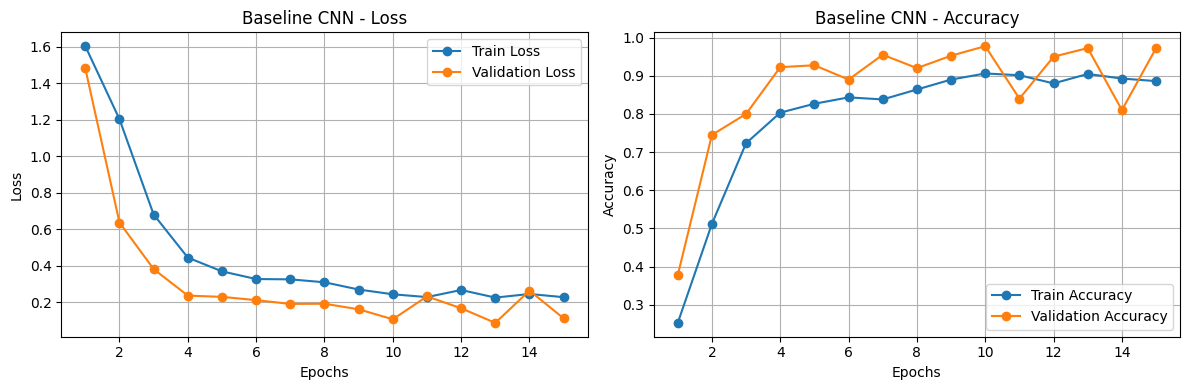

In [11]:
def plot_history(history, title_prefix="Model"):
    epochs = range(1, len(history["train_loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Plot train and evaluation loss
    axes[0].plot(epochs, history["train_loss"], label="Train Loss", marker='o')
    axes[0].plot(epochs, history["val_loss"], label="Validation Loss", marker='o')
    axes[0].set_title(f"{title_prefix} - Loss")
    axes[0].set_xlabel("Epochs")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[0].grid(True)

    # Plot train and evaluation accuracy
    axes[1].plot(epochs, history["train_acc"], label="Train Accuracy", marker='o')
    axes[1].plot(epochs, history["val_acc"], label="Validation Accuracy", marker='o')
    axes[1].set_title(f"{title_prefix} - Accuracy")
    axes[1].set_xlabel("Epochs")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()
    axes[1].grid(True)
    
    plt.tight_layout()
    plt.show()

plot_history(baseline_history, title_prefix="Baseline CNN")

## 10. Test Set Evaluation
The ultimate test of our model is its performance on unseen data. We evaluate the best saved model state on the test set, computing accuracy, precision, recall, and the macro F1-score. 

A Confusion Matrix is also plotted to identify which emoji emotions the model struggles to differentiate.

Baseline Test Accuracy : 0.9640
Baseline Test Precision: 0.9695
Baseline Test Recall   : 0.9640
Baseline Test F1-score : 0.9637

Classification report:
              precision    recall  f1-score   support

       happy       1.00      1.00      1.00       100
         sad       1.00      0.82      0.90       100
       angry       0.85      1.00      0.92       100
   surprised       1.00      1.00      1.00       100
      sleepy       1.00      1.00      1.00       100

    accuracy                           0.96       500
   macro avg       0.97      0.96      0.96       500
weighted avg       0.97      0.96      0.96       500



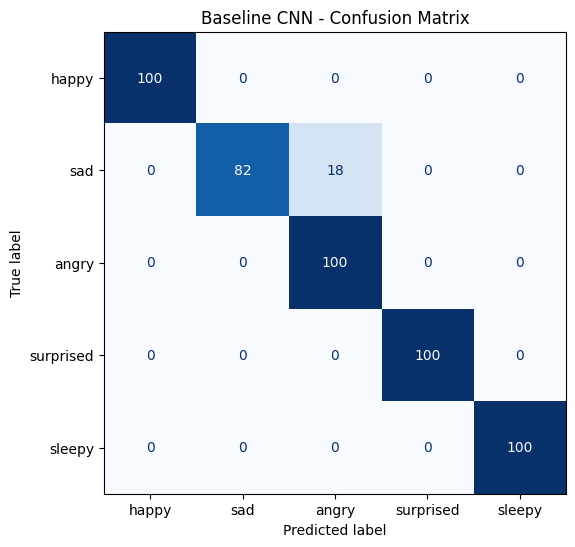

In [12]:
@torch.no_grad()
def predict_loader(model, loader, device):
    model.eval()
    all_probs, all_preds, all_targets = [], [], []

    for images, targets in loader:
        images = images.to(device)
        outputs = model(images)
        probs = torch.softmax(outputs, dim=1)
        preds = outputs.argmax(dim=1)

        all_probs.append(probs.cpu())
        all_preds.append(preds.cpu())
        all_targets.append(targets)

    all_probs = torch.cat(all_probs).numpy()
    all_preds = torch.cat(all_preds).numpy()
    all_targets = torch.cat(all_targets).numpy()
    return all_probs, all_preds, all_targets

# Get predictions
baseline_probs, baseline_preds, test_targets = predict_loader(baseline_model, test_loader, device)

# Calculate metrics
baseline_acc = accuracy_score(test_targets, baseline_preds)
baseline_prec, baseline_rec, baseline_f1, _ = precision_recall_fscore_support(test_targets, baseline_preds, average='macro')

print(f"Baseline Test Accuracy : {baseline_acc:.4f}")
print(f"Baseline Test Precision: {baseline_prec:.4f}")
print(f"Baseline Test Recall   : {baseline_rec:.4f}")
print(f"Baseline Test F1-score : {baseline_f1:.4f}")

print("\nClassification report:")
print(classification_report(test_targets, baseline_preds, target_names=CLASS_NAMES))

# Plot Confusion Matrix
cm = confusion_matrix(test_targets, baseline_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
plt.title("Baseline CNN - Confusion Matrix")
plt.show()

## 11. Error Analysis
To better understand the model's limitations, we extract and visualize instances where the network made incorrect predictions. 

*Qualitative Observation:* Errors are typically concentrated in the "hard mode" test set where heavy occlusions, blurring, and severe rotation mask critical features (like the shape of the mouth or eyes). Some emotions, like `sad` and `angry`, share similar structural features and are naturally harder to disambiguate when noise is introduced.

Number of mistakes: 18 / 500


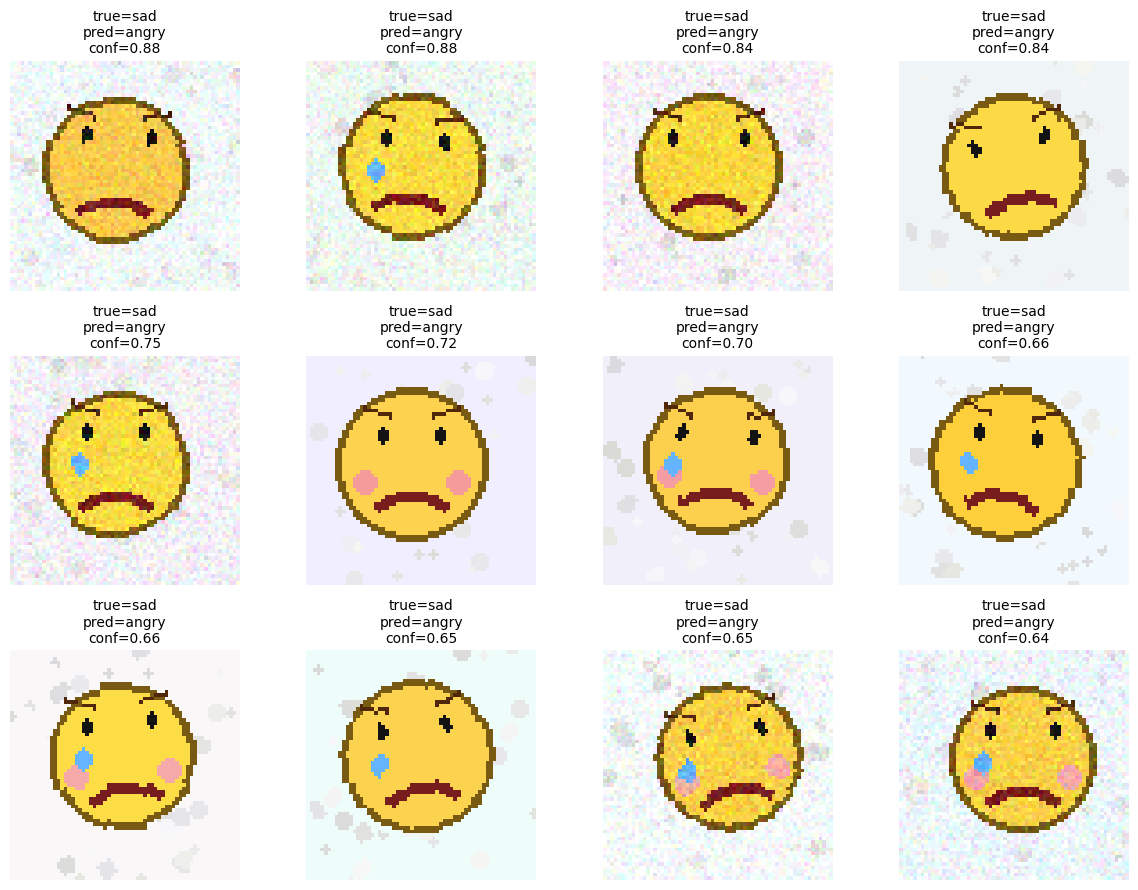

In [13]:
@torch.no_grad()
def collect_predictions_with_images(model, dataset, device, max_items=None):
    model.eval()
    items = []
    total = len(dataset) if max_items is None else min(len(dataset), max_items)

    for idx in range(total):
        # Collect image and label from dataset
        image, label = dataset[idx]

        # Add batch dimention and move to device
        img_tensor = image.unsqueeze(0).to(device)

        # Model prediction
        outputs = model(img_tensor)
        prob = torch.softmax(outputs, dim=1).squeeze(0) # Remove batch dimention
        pred = torch.argmax(prob).item()

        items.append({
            "image": image,
            "label": label,
            "pred": pred,
            "confidence": float(prob[pred].item()),
        })
    return items

test_items = collect_predictions_with_images(baseline_model, test_dataset, device)
mistakes = [item for item in test_items if item["label"] != item["pred"]]
mistakes = sorted(mistakes, key=lambda x: x["confidence"], reverse=True)

print(f"Number of mistakes: {len(mistakes)} / {len(test_items)}")

n_show = min(12, len(mistakes))
if n_show > 0:
    cols = 4
    rows = math.ceil(n_show / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(12, 3 * rows))
    axes = np.array(axes).reshape(rows, cols)

    for ax in axes.ravel():
        ax.axis("off")

    for i in range(n_show):
        item = mistakes[i]
        img = np.transpose(denormalize(item["image"]).numpy(), (1, 2, 0))
        ax = axes.ravel()[i]
        ax.imshow(img)
        ax.set_title(
            f"true={CLASS_NAMES[item['label']]}\npred={CLASS_NAMES[item['pred']]}\nconf={item['confidence']:.2f}",
            fontsize=10
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("Great! No mistakes found in the displayed set.")

## 12. Feature Map Visualization (Interpretability)
To verify that the CNN is learning meaningful spatial hierarchies rather than memorizing noise, we extract the activations from the first convolutional layer. This reveals the foundational edges, curves, and contrast boundaries the model uses to build its predictions.

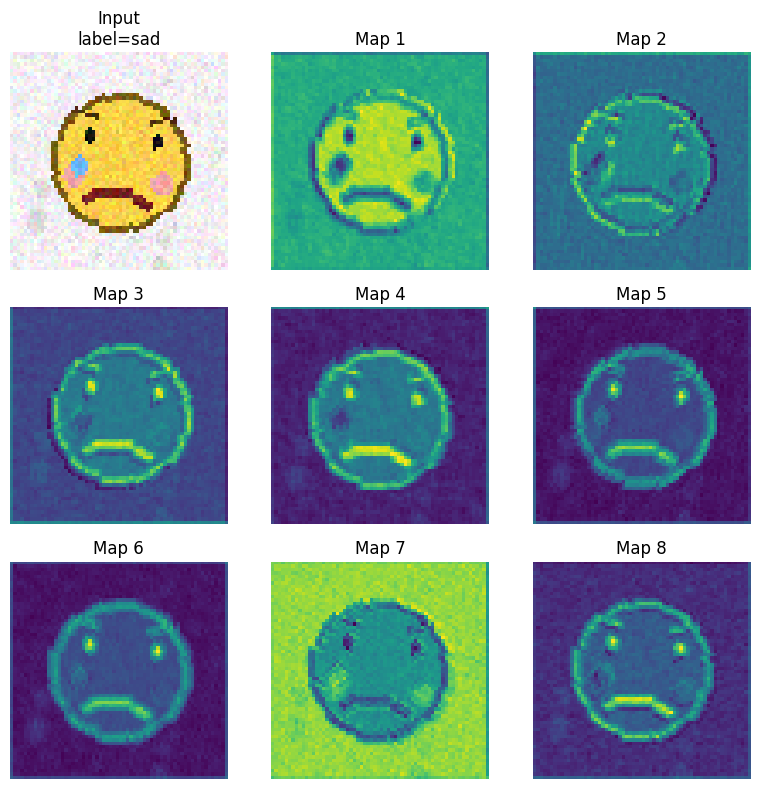

In [14]:
@torch.no_grad()
def show_feature_maps(model, dataset, sample_idx=0, n_maps=8):
    model.eval()
    image, label = dataset[sample_idx]
    x = image.unsqueeze(0).to(device)

    first_block = list(model.children())[0]
    fmap = first_block(x).squeeze(0).cpu()

    fig, axes = plt.subplots(3, 3, figsize=(8, 8))
    axes = axes.ravel()

    axes[0].imshow(np.transpose(denormalize(image).numpy(), (1, 2, 0)))
    axes[0].set_title(f"Input\nlabel={CLASS_NAMES[label]}")
    axes[0].axis("off")

    for i in range(1, min(n_maps + 1, 9)):
        axes[i].imshow(fmap[i - 1], cmap="viridis")
        axes[i].set_title(f"Map {i}")
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()

show_feature_maps(baseline_model, test_dataset, sample_idx=3, n_maps=8)

## 13. Optimized CNN Architecture
The baseline model demonstrates fundamental competency but can suffer from instability and overfitting during training. 

To improve robustness, we introduce the `BetterCNN` architecture. This version incorporates **Batch Normalization** to stabilize internal covariate shift, increases the feature map depth (32->64->128) to capture more complex patterns, and employs **Weight Decay (L2 Regularization)** in the optimizer.

In [18]:
class BetterCNN(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()

        # Feature extraction layers: responsible for learning spatial representations
        self.features = nn.Sequential(
            # Block 1: Input (3, 64, 64) -> Output (32, 32, 32)
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2), nn.Dropout2d(0.1),
            
            # Block 2: Input (32, 32, 32) -> Output (64, 16, 16)
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2), nn.Dropout2d(0.2),
            
            # Block 3: Input (64, 16, 16) -> Output (128, 8, 8)
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2), nn.Dropout2d(0.3),
            
            # Block 4: Input (128, 8, 8) -> Output (128, 8, 8)
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            
            # Adaptive Pool: Reduces any spatial dimension to 2x2, 
            # output shape: (batch_size, 128, 2, 2)
            nn.AdaptiveAvgPool2d((2, 2))
        )
        
        # Classification head: translates features into class probabilities
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128*2*2, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.5),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        
        return x

better_model = BetterCNN(num_classes=5).to(device)
print(better_model)
print(f"Trainable params: {count_trainable_params(better_model):,}")

BetterCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Dropout2d(p=0.1, inplace=False)
    (5): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): ReLU(inplace=True)
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Dropout2d(p=0.2, inplace=False)
    (10): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (12): ReLU(inplace=True)
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (14): Dropout2d(p=0.3, inplace=False)
    (1

Epoch 01 | train_loss=1.6017 train_acc=0.2447 | val_loss=1.5827 val_acc=0.2300
Epoch 02 | train_loss=1.5326 train_acc=0.3373 | val_loss=1.6118 val_acc=0.2000
Epoch 03 | train_loss=1.3979 train_acc=0.4353 | val_loss=1.9249 val_acc=0.2000
Epoch 04 | train_loss=1.2268 train_acc=0.5333 | val_loss=0.9898 val_acc=0.6725
Epoch 05 | train_loss=1.0221 train_acc=0.6460 | val_loss=0.7273 val_acc=0.8325
Epoch 06 | train_loss=0.8503 train_acc=0.7033 | val_loss=0.5692 val_acc=0.8525
Epoch 07 | train_loss=0.6834 train_acc=0.7540 | val_loss=0.4094 val_acc=0.8700
Epoch 08 | train_loss=0.5518 train_acc=0.8073 | val_loss=0.3481 val_acc=0.9150
Epoch 09 | train_loss=0.4469 train_acc=0.8227 | val_loss=0.2834 val_acc=0.9125
Epoch 10 | train_loss=0.3847 train_acc=0.8440 | val_loss=0.2483 val_acc=0.9300
Epoch 11 | train_loss=0.3565 train_acc=0.8500 | val_loss=0.2382 val_acc=0.8975
Epoch 12 | train_loss=0.3177 train_acc=0.8600 | val_loss=0.2024 val_acc=0.9625
Epoch 13 | train_loss=0.2804 train_acc=0.8840 | val_

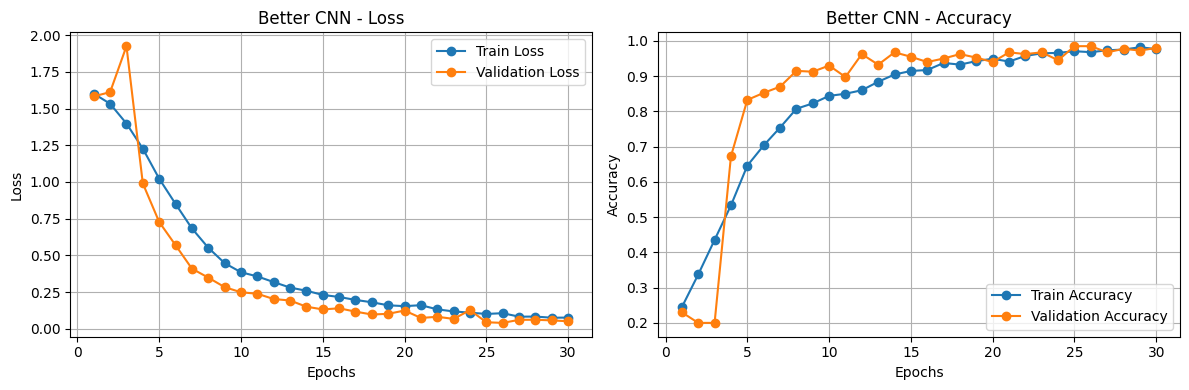

In [19]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(better_model.parameters(), lr=3e-4, weight_decay=1e-2)

better_history = fit_model(
    better_model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    device,
    epochs=30,
    patience=4,
)

plot_history(better_history, title_prefix="Better CNN")

,model,accuracy,precision_macro,recall_macro,f1_macro,params
0,BaselineCNN,0.964,0.969492,0.964,0.963706,548645
1,BetterCNN,0.986,0.986916,0.986,0.985983,307845


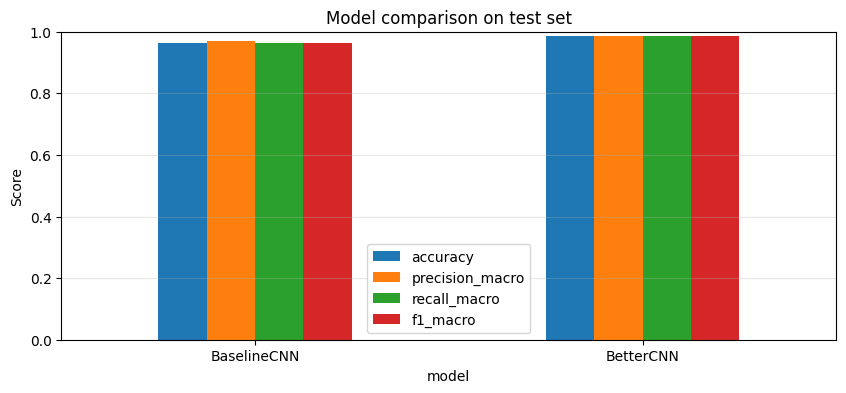

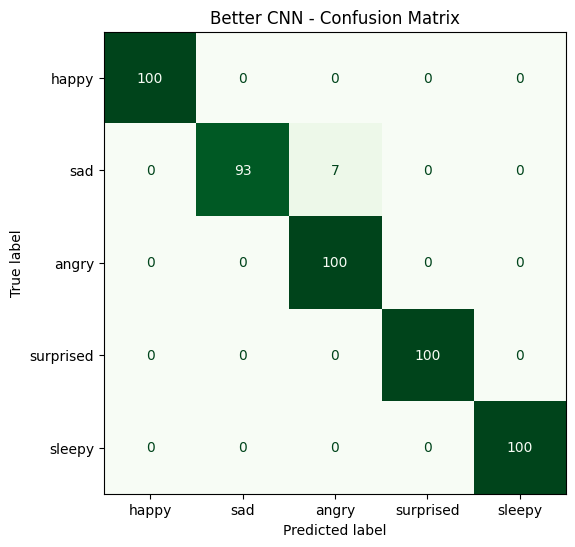

In [21]:
better_probs, better_preds, test_targets = predict_loader(better_model, test_loader, device)

better_acc = accuracy_score(test_targets, better_preds)
better_prec, better_rec, better_f1, _ = precision_recall_fscore_support(test_targets, better_preds, average="macro", zero_division=0)

comparison_df = pd.DataFrame([
    {
        "model": "BaselineCNN",
        "accuracy": baseline_acc,
        "precision_macro": baseline_prec,
        "recall_macro": baseline_rec,
        "f1_macro": baseline_f1,
        "params": count_trainable_params(baseline_model),
    },
    {
        "model": "BetterCNN",
        "accuracy": better_acc,
        "precision_macro": better_prec,
        "recall_macro": better_rec,
        "f1_macro": better_f1,
        "params": count_trainable_params(better_model),
    },
])

display(comparison_df)

comparison_df.set_index("model")[["accuracy", "precision_macro", "recall_macro", "f1_macro"]].plot(
    kind="bar", figsize=(10, 4)
)
plt.ylim(0, 1.0)
plt.ylabel("Score")
plt.title("Model comparison on test set")
plt.grid(axis="y", alpha=0.3)
plt.xticks(rotation=0)
plt.show()

cm_better = confusion_matrix(test_targets, better_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_better, display_labels=CLASS_NAMES)
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap="Greens", values_format="d", colorbar=False)
plt.title("Better CNN - Confusion Matrix")
plt.show()

## 14. Conclusion and Future Work
The implementation of `BetterCNN` alongside a robust data augmentation pipeline successfully addresses the challenges of noise, occlusion, and variance in the procedural dataset. The inclusion of Batch Normalization noticeably smoothed the loss curve and accelerated convergence.

**Future Improvements:**
* **Transfer Learning:** Fine-tuning a pre-trained lightweight model like MobileNetV2 for comparison.
* **Label Smoothing:** Applying label smoothing to the loss function to reduce overconfidence on noisy targets.
* **Advanced Explainability:** Implementing Grad-CAM to visualize precisely which pixels the network relies on to make its final prediction.